In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats

### A little function to help us know the significance of our p-value

In [2]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return "ns"

### Read in the data file with all the fissions

In [3]:
custom_palette = ['#0BD566','#F27B40']

df = pd.read_csv('Fissions.csv')

# Split the data by fission type to tell if their distances to the MTOC are significantly different
df_periph = df.loc[df['Type'] == 'Peripheral', ['Length']]
df_midzone = df.loc[df['Type'] == 'Midzone', ['Length']]

Perform a T-test on midzone and peripheral fission distance to MTOC

In [4]:
stat, pvalue = stats.ttest_ind(df_periph, df_midzone)
convert_pvalue_to_asterisks(pvalue)

'***'

In [7]:
df.head()

,Number,Area,Mean,Min,Max,Angle,Length,Cellsize,Cell,Type
0,2,1.697,147.570,113.367,380.000,-166.504,30.235,5194.21,A,Peripheral
1,3,1.010,155.920,119.673,261.354,52.595,17.977,5194.21,A,Peripheral
2,4,1.098,153.454,118.615,295.000,81.104,19.555,5194.21,A,Peripheral
3,5,1.596,171.929,116.739,294.567,-18.221,28.476,5194.21,A,Midzone
4,6,1.223,205.434,124.460,337.058,-41.560,21.779,5194.21,A,Midzone


### Fission type and distanct to MTOC

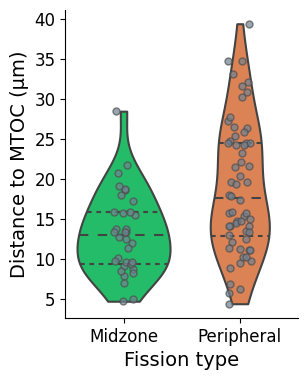

In [9]:
fig, ax = plt.subplots(figsize=(3, 4))

sns.violinplot(x='Type', y='Length', data=df, palette=sns.color_palette(custom_palette), inner='quartile', cut=0, order=['Midzone', 'Peripheral'])
sns.stripplot(x='Type', y='Length', data=df, color='slategray', linewidth=1, alpha=0.7, order=['Midzone', 'Peripheral'])
plt.xlabel('Fission type', fontsize=14)
plt.xticks(fontsize=12)
plt.ylabel('Distance to MTOC (µm)', fontsize=14)
plt.yticks(fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

#plt.show()
plt.savefig('fission_distance_to_MTOC.png', dpi=300, bbox_inches='tight')